# 10: What the keyword count misses

**DATA 5500, Senior Design**

**Sara Choque Molina**

Notebook 09 labeled the full 2021 corpus and verified those labels: on whether an article reports a threat, the model agrees with a blind human reading 93.3% of the time. Q4 and Q5 are measured on raw keyword counts. The project argues these measures are unreliable.

2021 is the period with article text, so it is where both measures exist. Here we compare them and measure the difference between what the keyword search counts and what the model classifies as a threat.

| File | Contents |
|---|---|
| `labels_predicted_full.csv` | Every 2021 article with its label, source and confidence, from notebook 09 |
| `02_articles_2021_tiktok.csv` | The GDELT export, which carries the publication day |
| `12_daily_total_2021_tiktok.csv` | The daily keyword counts, frome those dates cover.

## Block 1: The date

The labels carry a URL and no date, and daily counts need one. The GDELT export carries both, so we join on URL. Where a URL appears on several days, we keep the earliest, which is the day the article entered the coverage.

Three checks come before any counting. Whether a URL appears on more than one day, since that would turn one article into several rows. How many labeled articles come out with a date and the range those dates cover.

In [14]:
import os
import pandas as pd

FOLDER = r"C:\Users\sara_\Desktop\College\DATA 5500-01 Senior Des\data bases"

labels = pd.read_csv(os.path.join(FOLDER, "labels_predicted_full.csv"))
gdelt = pd.read_csv(os.path.join(FOLDER, "02_articles_2021_tiktok.csv"))

print("Labeled articles:", len(labels))
print("GDELT rows:", len(gdelt))
print("Urls appearing on more than one day:", len(gdelt) - gdelt["url"].nunique())
print()

# An article republished across days would otherwise be counted once per day, so each
# url keeps its earliest appearance.
first_day = gdelt.sort_values("day").drop_duplicates("url")[["url", "day"]]

dated = labels.merge(first_day, on="url", how="left")
# The day comes as 20211115 and becomes a real date so the counts can be grouped by it.
dated["date"] = pd.to_datetime(dated["day"].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

print("Labeled articles with a date:", int(dated["date"].notna().sum()), "of", len(dated))
print("Without a date:", int(dated["date"].isna().sum()))
print("Date range:", dated["date"].min().date(), "to", dated["date"].max().date())

Labeled articles: 1554
GDELT rows: 4995
Urls appearing on more than one day: 0

Labeled articles with a date: 1554 of 1554
Without a date: 0
Date range: 2021-11-15 to 2022-01-14


**Results**

- No URL appears on more than one day, so each article enters the daily count once and the join adds no rows.
- All 1,554 labeled articles received a date.
- The window runs 2021-11-15 to 2022-01-14, two months around the December spike.

## Block 2: Two daily series

Both series come from the same 1,554 articles. The first counts every article the keyword search returned and we could read. The second counts the ones the model classified as a threat, targeted or nontargeted.

A third series repeats the second using the predictions the model was most sure of, those at 0.5 confidence or above, together with the 136 a person labeled. Comparing it against the second shows whether the shape depends on the weaker predictions.

Days with no articles are filled with zero so the series runs continuously.

In [18]:
dated["threat"] = dated["label"] != "unrelated"

# Human labels carry no confidence value and always count
# A predicted one joins the second series when the model reaches 0.5.
over_05 = dated[dated["confidence"].isna() | (dated["confidence"] >= 0.5)]

days = pd.date_range(dated["date"].min(), dated["date"].max(), freq="D")

daily = pd.DataFrame({
    "articles": dated.groupby("date").size(),
    "threats": dated.groupby("date")["threat"].sum(),
    "threats_over_05": over_05.groupby("date")["threat"].sum(),
}).reindex(days).fillna(0).astype(int)

daily.index.name = "date"
# Days with no articles would divide by zero, so they are left empty.
daily["threat_%"] = (daily["threats"] / daily["articles"].where(daily["articles"] > 0) * 100).round(2)
daily = daily[["articles", "threats", "threat_%", "threats_over_05"]]

print("Days in the window:", len(daily))
print()
print("Articles returned by the keyword search and readable:", daily["articles"].sum())
print("Classified as a threat:", daily["threats"].sum())
print("Classified as a threat, confidence 0.5 or above:", daily["threats_over_05"].sum())
print("Share classified as a threat:", round(daily["threats"].sum() / daily["articles"].sum() * 100, 2), "%")

daily.sort_values("articles", ascending=False).head(5)

Days in the window: 61

Articles returned by the keyword search and readable: 1554
Classified as a threat: 1200
Classified as a threat, confidence 0.5 or above: 679
Share classified as a threat: 77.22 %


,articles,threats,threat_%,threats_over_05
date,,,,
2021-12-17,289,271,93.77,208
2021-12-09,95,79,83.16,38
2021-12-16,87,79,90.80,57
2021-12-08,80,68,85.00,34
2021-12-03,77,61,79.22,29


**Results**

- 1,200 of the 1,554 readable articles are classified as a threat, 77.22%. This pools the five categories the query pulled, and block 4 separates them.
- Both series peak on the same day, 2021-12-17, with 289 articles returned and 271 classified as threats. The w's shapeave survives the classification.
- On that peak, day the threat share reaches 93.77%, against 77.22% across the window, so the share runs higher at the peak than away from it.
- The series limited to confidence 0.5 or above holds 679 articles. It drops every prediction under 0.5, including threats, so it sits under the full series by construction and is read for shape rather than level.

## Block 3: The two series side by side

The figure puts the three series on one axis across the 61 days. The distance between the first two is the share of what the keyword search returned that the model reads as something other than a threat.

The dashed line carries the stronger predictions. It sits below the others by construction, since it drops every prediction under 0.5 including the threats, so it is read for its shape.

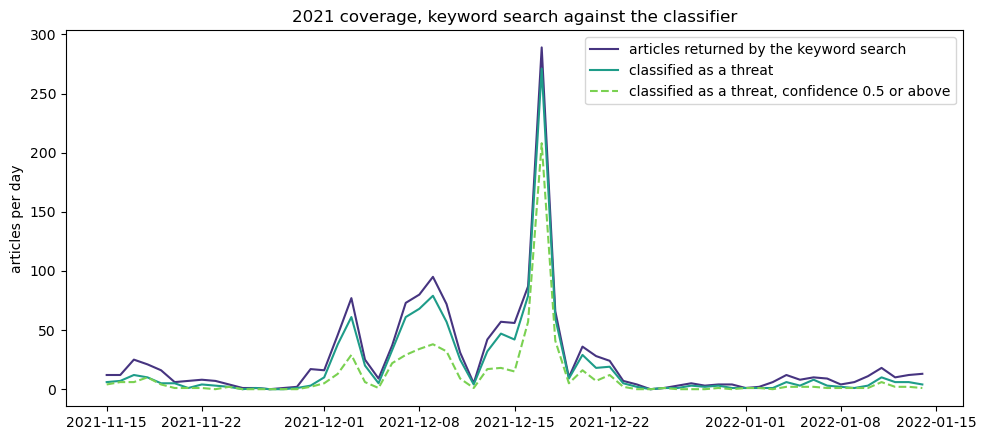

In [19]:
import matplotlib.pyplot as plt

colors = plt.cm.viridis([0.15, 0.55, 0.8])

plt.figure(figsize=(10, 4.5))
plt.plot(daily.index, daily["articles"], color=colors[0], label="articles returned by the keyword search")
plt.plot(daily.index, daily["threats"], color=colors[1], label="classified as a threat")
plt.plot(daily.index, daily["threats_over_05"], color=colors[2], linestyle="--",
         label="classified as a threat, confidence 0.5 or above")

plt.ylabel("articles per day")
plt.title("2021 coverage, keyword search against the classifier")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FOLDER, "figures", "10_keyword_vs_classified.png"), dpi=200)
plt.show()

**Results**

- The three lines rise and fall together across the 61 days. Classifying the articles moves the level of the series and leaves the shape of the wave in place.
- The peak sits on 2021-12-17 in all three, and the two solid lines nearly meet there.
- The dashed line runs under the others through the whole window and follows the same path, so the shape holds without the predictions the model was least sure of.

## Block 4: Precision by category

The GDELT export tags every link with the category the query matched. The query pulled five: `student_threat` and four others that act as controls, among them `pandemic` and `school_board`, which the codebook treats as unrelated.

Here we count, inside each category, how many of its readable articles the model classifies as a threat. The `student_threat` row is the precision of the search for the thing it was looking for. The control rows say whether the model agrees that they are something else.

In [21]:
# The export tags each link with the category the query matched, so the comparison runs
# against the bucket that claimed to be about student threats.
categories = gdelt.sort_values("day").drop_duplicates("url")[["url", "category"]]
tagged = dated.merge(categories, on="url", how="left")

by_category = tagged.groupby("category").agg(
    articles=("threat", "size"),
    threats=("threat", "sum"),
)
by_category["threat_%"] = (by_category["threats"] / by_category["articles"] * 100).round(2)

print("Links returned by the keyword search:", len(gdelt))
print("Readable and in the corpus:", len(tagged))
print("Readable %:", round(len(tagged) / len(gdelt) * 100, 2))
print()

by_category.sort_values("articles", ascending=False)

Links returned by the keyword search: 4995
Readable and in the corpus: 1554
Readable %: 31.11



,articles,threats,threat_%
category,,,
student_threat,1353,1144,84.55
other,98,41,41.84
pandemic,70,12,17.14
school_board,24,2,8.33
shooting_event,9,1,11.11


**Results**

- Inside the bucket the query was built for, `student_threat`, 84.55% of the readable articles are classified as threats. About one in six is something else, and this is the precision figure the project carries forward.
- The 77.22% in block 2 pools all five categories, including ones the codebook sends to `unrelated`, so it understates what the search does with the bucket it was aiming at.
- The control categories land where the codebook puts them: `school_board` at 8.33% and `pandemic` at 17.14%. The model reaches that from the text alone, which checks it from a direction the annotation never touched.
- 31.11% of the links returned could be read. That belongs to the extraction pipeline rather than to the search, and the two are reported separately.

## Block 5: Does the error rate move with the wave

Q4 measures how long a wave runs above its normal level, counted on the links the keyword search returned. If the share of those links that are really threats stays flat across the wave, the keyword count is a fixed multiple of the true count and Q4's answer holds. If the share moves, the shape of the wave moves with it.

Here we take the `student_threat` links per day from notebook 05, join the readable articles we classified, and compare the threat share during the week around the peak, 14 to 20 December, against the rest of the window.

In [23]:
daily_categories = pd.read_csv(os.path.join(FOLDER, "05_daily_categories_2021_tiktok.csv"))

links = daily_categories[daily_categories["category"] == "student_threat"]
links = links[["day", "articles"]].rename(columns={"articles": "links"}).set_index("day")

read_and_classified = tagged[tagged["category"] == "student_threat"].groupby("day").agg(
    readable=("threat", "size"),
    threats=("threat", "sum"),
)

student = links.join(read_and_classified)
student["readable_%"] = (student["readable"] / student["links"] * 100).round(2)
student["threat_%"] = (student["threats"] / student["readable"] * 100).round(2)

# The peak sits on 17 December, so the comparison takes the week around it.
peak_week = (student.index >= 20211214) & (student.index <= 20211220)

for name, part in [("peak week", student[peak_week]), ("the rest", student[~peak_week])]:
    share = round(part["threats"].sum() / part["readable"].sum() * 100, 2)
    print(f"{name:10} links {int(part['links'].sum()):5}   readable {int(part['readable'].sum()):5}"
          f"   threats {int(part['threats'].sum()):5}   threat % {share}")

print()
student.sort_values("links", ascending=False).head(8)

peak week  links  1865   readable   563   threats   519   threat % 92.18
the rest   links  2401   readable   790   threats   625   threat % 79.11



,links,readable,threats,readable_%,threat_%
day,,,,,
20211217,1004,282.0,267.0,28.09,94.68
20211218,271,66.0,60.0,24.35,90.91
20211202,254,43.0,37.0,16.93,86.05
20211209,237,86.0,75.0,36.29,87.21
20211203,213,73.0,61.0,34.27,83.56
20211210,211,64.0,55.0,30.33,85.94
20211208,206,71.0,64.0,34.47,90.14
20211216,202,77.0,72.0,38.12,93.51


**Results**

- The threat share runs 92.18% during the peak week and 79.11% across the rest of the window, a gap of 13 points. The keyword count is not a fixed multiple of the true count.
- The gap runs one way: the search is cleaner when the wave is loud and noisier when it is quiet. Correcting for it would pull the quiet days down further than the peak. It would pull toward a sharper wave rather than a longer one.
- Recomputing the days above normal on corrected counts stays out of reach. The baseline comes from years with no article text, so only one side of that comparison can be corrected.
- The readable share swings between 16.93% and 38.12% across these days, so each daily threat share rests on a different sample size.

## Block 6: Targeted and nontargeted across the wave

The threat decision is the primary analysis of this project. The split between targeted and nontargeted threats is secondary and exploratory: it carries a kappa of 0.585 against a blind human reading, against 0.690 for the threat decision, so what follows reads as a direction rather than a precise level.

Here we take the articles classified as threats and count, week by week, how many of them name the school that was threatened.

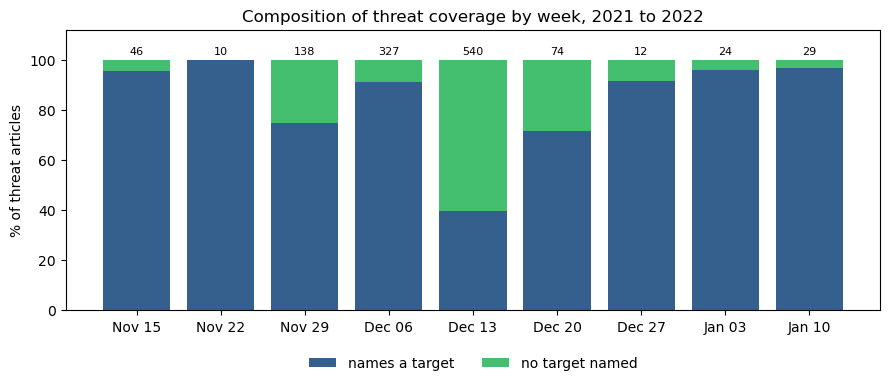

In [28]:
# The weeks go in as text so the bars sit evenly spaced and the labels stay short.
weeks = weekly.index.strftime("%b %d")
share = weekly[["targeted_threat", "nontargeted_threat"]].div(weekly["threats"], axis=0) * 100

plt.figure(figsize=(9, 4))
plt.bar(weeks, share["targeted_threat"], color=plt.cm.viridis(0.3), label="names a target")
plt.bar(weeks, share["nontargeted_threat"], bottom=share["targeted_threat"],
        color=plt.cm.viridis(0.7), label="no target named")

# Each bar is a share, so the article count it rests on goes above it.
for position, count in enumerate(weekly["threats"]):
    plt.text(position, 102, count, ha="center", fontsize=8)

plt.ylim(0, 112)
plt.ylabel("% of threat articles")
plt.title("Composition of threat coverage by week, 2021 to 2022")
plt.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FOLDER, "figures", "10_targeted_share_by_week.png"), dpi=200)
plt.show()

**Results**

- Outside the week of 13 December, between 71.62% and 100% of threat articles name the school that was threatened. In that week the share falls to 39.44%, with 327 of 540 articles naming no target.
- The swing runs about 56 points and sits inside one week. The subclass distinction carries a kappa of 0.585, which blurs a difference of a few points. It does not produce a move of this size in a single week.
- Reporting on individual named schools gives way to reporting on the trend itself, and returns to named schools the week after.

## Conclusions

| | |
|---|---|
| Links the keyword search returned | 4,995 |
| Readable and classified | 1,554, 31.11% |
| Threats inside the `student_threat` bucket | 84.55% |
| Threat share, peak week | 92.18% |
| Threat share, rest of the window | 79.11% |

**The keyword search returns a threat 84.55% of the time inside the bucket it was built for.** About one in six is something else. Counting threats by keyword match overstates the volume, by a measured amount rather than an asserted one.

The error does not sit evenly across the window. Correcting the counts would pull the quiet days down further than the peak, so Q4 and Q5 stay on keyword counts and that direction supports their answer rather than working against it. The control categories close the loop from another side: `school_board` at 8.33% and `pandemic` at 17.14% land where the codebook puts them, reached from the text alone.

**Secondary and exploratory.** In the week of 13 December the share of threat articles naming a target falls to 39.44%, against 71.62% to 100% in every other week. Coverage moves from individual schools to the trend itself and returns the week after. The subclass distinction carries a kappa of 0.585, so this reads as a direction, and a swing of that size does not come from label noise.

**Limits**

- One period. 2021 carries article text and the other four do not, so these figures describe the TikTok case.
- 31.11% of the links could be read. That belongs to the extraction pipeline, and the articles behind the rest are unknown.
- The baseline years carry no article text, so the days above normal cannot be corrected on both sides of that comparison.
- The daily threat shares rest on uneven sample sizes, since the readable share moves from day to day.

**Next steps (#TODO later)**

- #TODO: Use SHAP with a text masker on the model for Q2.
- #TODO: Carry 84.55% rather than 77.22% as the precision figure in the final report.